In [1]:
#importing relevant libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

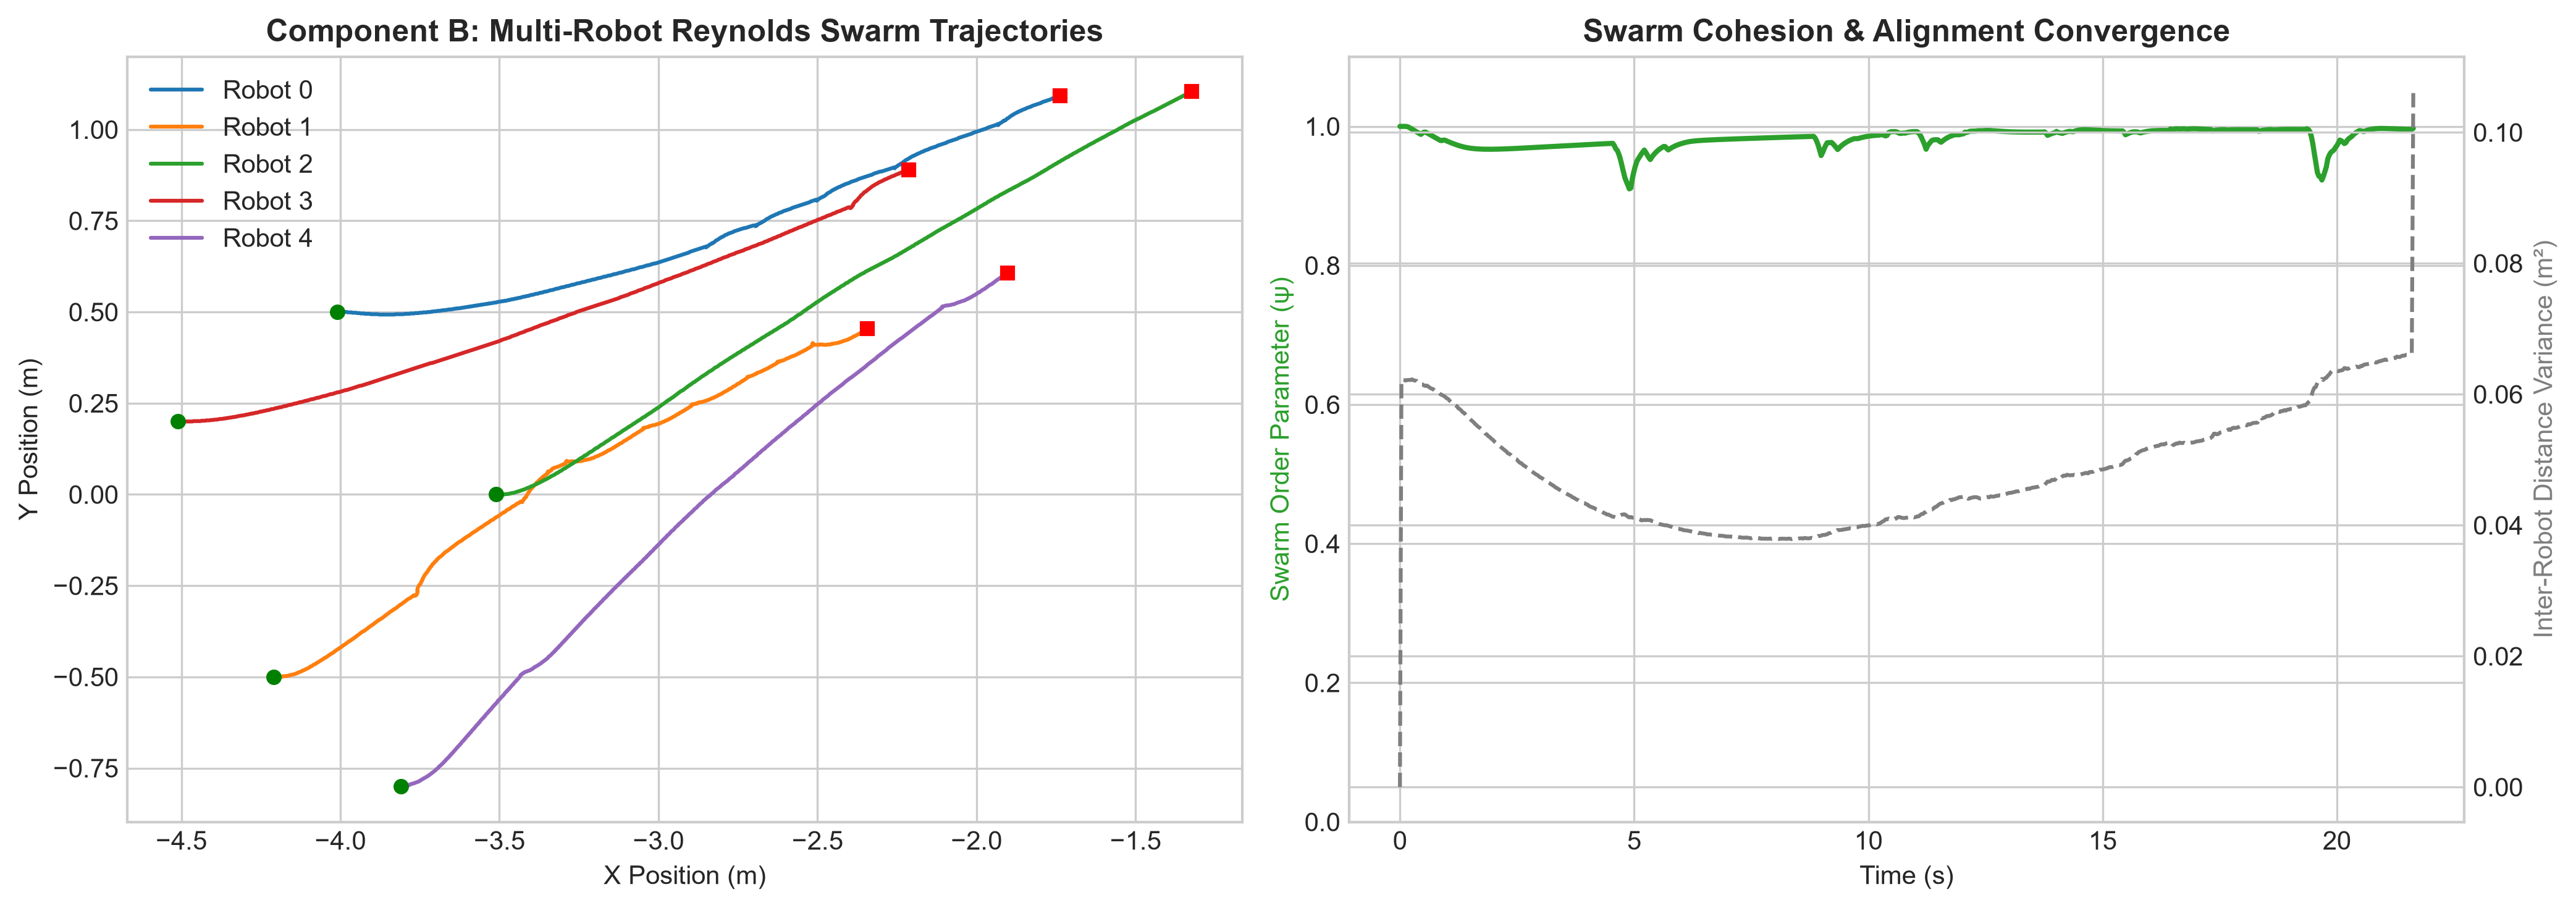

In [8]:
#telemetry is generated  and loaded by Webots Robot 0
csv_path = r'C:\Users\User\OneDrive\Desktop\2026_SecondSemester\Assignments\robotics_assignment\component_b_swarm_system\controllers\b_swarm_controller\swarm_telemetry.csv'
df = pd.read_csv(csv_path)

#the unique simulation time steps must be instantiated to compute swarm dynamics metrics over time
time_steps = df['time'].unique()

swarm_trajectories = {r_id: df[df['robot_id'] == r_id] for r_id in df['robot_id'].unique()}
alignment_order = []
inter_robot_variance = []

#Swarm Dynamics Metrics over Time
for t in time_steps:
    sub_df = df[df['time'] == t]
    if len(sub_df) > 1:
        # 1. Swarm Heading Alignment Order Parameter (psi)
        headings = sub_df['heading'].values
        mean_cx = np.mean(np.cos(headings))
        mean_sy = np.mean(np.sin(headings))
        psi = np.hypot(mean_cx, mean_sy)
        alignment_order.append(psi)

        # 2. Inter-Robot Spatial Variance
        positions = sub_df[['x', 'y']].values
        dists = []
        for i in range(len(positions)):
            for j in range(i + 1, len(positions)):
                dists.append(np.linalg.norm(positions[i] - positions[j]))
        inter_robot_variance.append(np.var(dists))
    else:
        alignment_order.append(1.0)
        inter_robot_variance.append(0.0)

# Set publication-quality styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

# Plot 1: 2D Multi-Robot Swarm Trajectories
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for r_id, r_df in swarm_trajectories.items():
    ax1.plot(r_df['x'], r_df['y'], label=f'Robot {int(r_id)}', color=colors[int(r_id) % len(colors)], linewidth=1.5)
    ax1.plot(r_df['x'].iloc[0], r_df['y'].iloc[0], 'go', markersize=5)   # Spawn point
    ax1.plot(r_df['x'].iloc[-1], r_df['y'].iloc[-1], 'rs', markersize=5) # Convergence point

ax1.set_title('Component B: Multi-Robot Reynolds Swarm Trajectories', fontsize=12, fontweight='bold')
ax1.set_xlabel('X Position (m)')
ax1.set_ylabel('Y Position (m)')
ax1.legend(loc='best')
ax1.grid(True)

# Plot 2: Alignment Order Parameter & Spatial Variance
ax2.plot(time_steps, alignment_order, color='#2ca02c', linewidth=2, label='Alignment Order (ψ)')
ax2_twin = ax2.twinx()
ax2_twin.plot(time_steps, inter_robot_variance, color='#7f7f7f', linestyle='--', linewidth=1.5, label='Distance Variance')

ax2.set_title('Swarm Cohesion & Alignment Convergence', fontsize=12, fontweight='bold')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Swarm Order Parameter (ψ)', color='#2ca02c')
ax2_twin.set_ylabel('Inter-Robot Distance Variance (m²)', color='#7f7f7f')
ax2.set_ylim(0, 1.1)

plt.tight_layout()

# Save before displaying canvas
plt.savefig('component_b_swarm_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

Handling  empty files

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

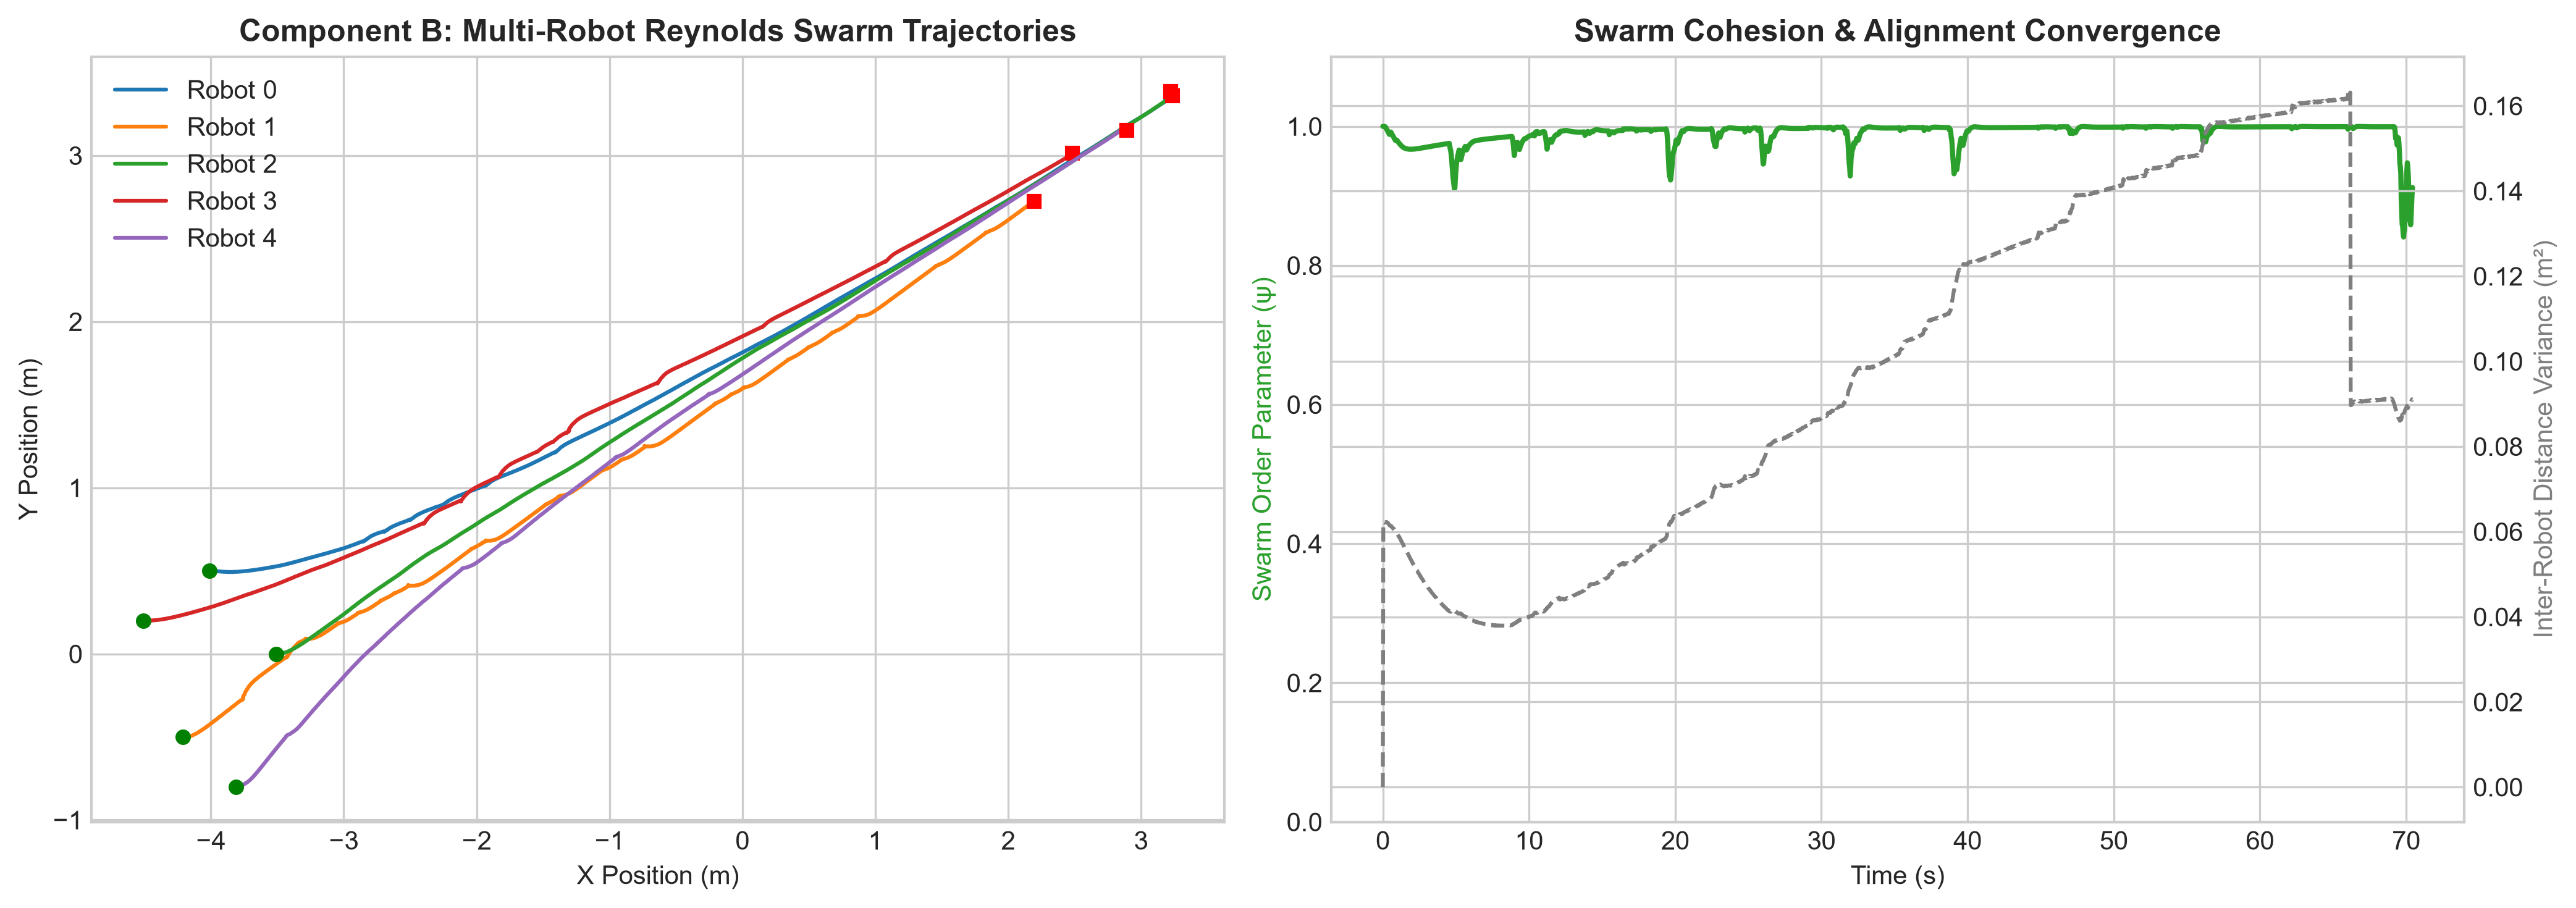

In [10]:
csv_path = r'C:\Users\User\OneDrive\Desktop\2026_SecondSemester\Assignments\robotics_assignment\component_b_swarm_system\controllers\b_swarm_controller\swarm_telemetry.csv'

# Check if file exists and has content
if not os.path.exists(csv_path) or os.path.getsize(csv_path) == 0:
    print("WARNING: swarm_telemetry.csv is empty or missing!")
    print("Please hit 'PLAY' in Webots for 10-15 seconds, then press 'PAUSE' to flush data to disk.")
else:
    df = pd.read_csv(csv_path)
    
    # Unique simulation time steps
    time_steps = df['time'].unique()

    swarm_trajectories = {r_id: df[df['robot_id'] == r_id] for r_id in df['robot_id'].unique()}
    alignment_order = []
    inter_robot_variance = []

    # Compute Swarm Dynamics Metrics over Time
    for t in time_steps:
        sub_df = df[df['time'] == t]
        if len(sub_df) > 1:
            # 1. Swarm Heading Alignment Order Parameter (psi)
            headings = sub_df['heading'].values
            mean_cx = np.mean(np.cos(headings))
            mean_sy = np.mean(np.sin(headings))
            psi = np.hypot(mean_cx, mean_sy)
            alignment_order.append(psi)

            # 2. Inter-Robot Spatial Variance
            positions = sub_df[['x', 'y']].values
            dists = []
            for i in range(len(positions)):
                for j in range(i + 1, len(positions)):
                    dists.append(np.linalg.norm(positions[i] - positions[j]))
            inter_robot_variance.append(np.var(dists))
        else:
            alignment_order.append(1.0)
            inter_robot_variance.append(0.0)

    # Publication-Quality Plots
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

    # Plot 1: 2D Multi-Robot Swarm Trajectories
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    for r_id, r_df in swarm_trajectories.items():
        ax1.plot(r_df['x'], r_df['y'], label=f'Robot {int(r_id)}', color=colors[int(r_id) % len(colors)], linewidth=1.5)
        ax1.plot(r_df['x'].iloc[0], r_df['y'].iloc[0], 'go', markersize=5)   # Start
        ax1.plot(r_df['x'].iloc[-1], r_df['y'].iloc[-1], 'rs', markersize=5) # Convergence

    ax1.set_title('Component B: Multi-Robot Reynolds Swarm Trajectories', fontsize=12, fontweight='bold')
    ax1.set_xlabel('X Position (m)')
    ax1.set_ylabel('Y Position (m)')
    ax1.legend(loc='best')
    ax1.grid(True)

    # Plot 2: Alignment Order Parameter & Spatial Variance
    ax2.plot(time_steps, alignment_order, color='#2ca02c', linewidth=2, label='Alignment Order (ψ)')
    ax2_twin = ax2.twinx()
    ax2_twin.plot(time_steps, inter_robot_variance, color='#7f7f7f', linestyle='--', linewidth=1.5, label='Distance Variance')

    ax2.set_title('Swarm Cohesion & Alignment Convergence', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Swarm Order Parameter (ψ)', color='#2ca02c')
    ax2_twin.set_ylabel('Inter-Robot Distance Variance (m²)', color='#7f7f7f')
    ax2.set_ylim(0, 1.1)

    plt.tight_layout()
    plt.savefig('component_b_swarm_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

In [2]:
pip install scikit-learn


   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.3 MB 2.6 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.3 MB 4.2 MB/s eta 0:00:02
   ------------------------------- -------- 6.6/8.3 MB 8.1 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.3 MB 7.2 MB/s eta 0:00:01
   -------------------------------------- - 7.9/8.3 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 5.8 MB/s  0:00:01
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   --- ------------------------------------ 3.4/36.7 MB 25.2 MB/s eta 0:00:02
   --- ------------------------------------ 3.4/36.7 MB 25.2 MB/s eta 0:00:02
   --- ------------------------------------ 3.4/36.7 MB 25.2 MB/s eta 0:00:02
   ---- ----------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Importing libraries and modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Neural Network Steering Classifier Trained.
Test Accuracy: 99.00%

Classification Report:
              precision    recall  f1-score   support

   Turn Left       1.00      1.00      1.00       244
  Turn Right       0.99      1.00      0.99       218
     Forward       0.95      0.92      0.93        38

    accuracy                           0.99       500
   macro avg       0.98      0.97      0.97       500
weighted avg       0.99      0.99      0.99       500



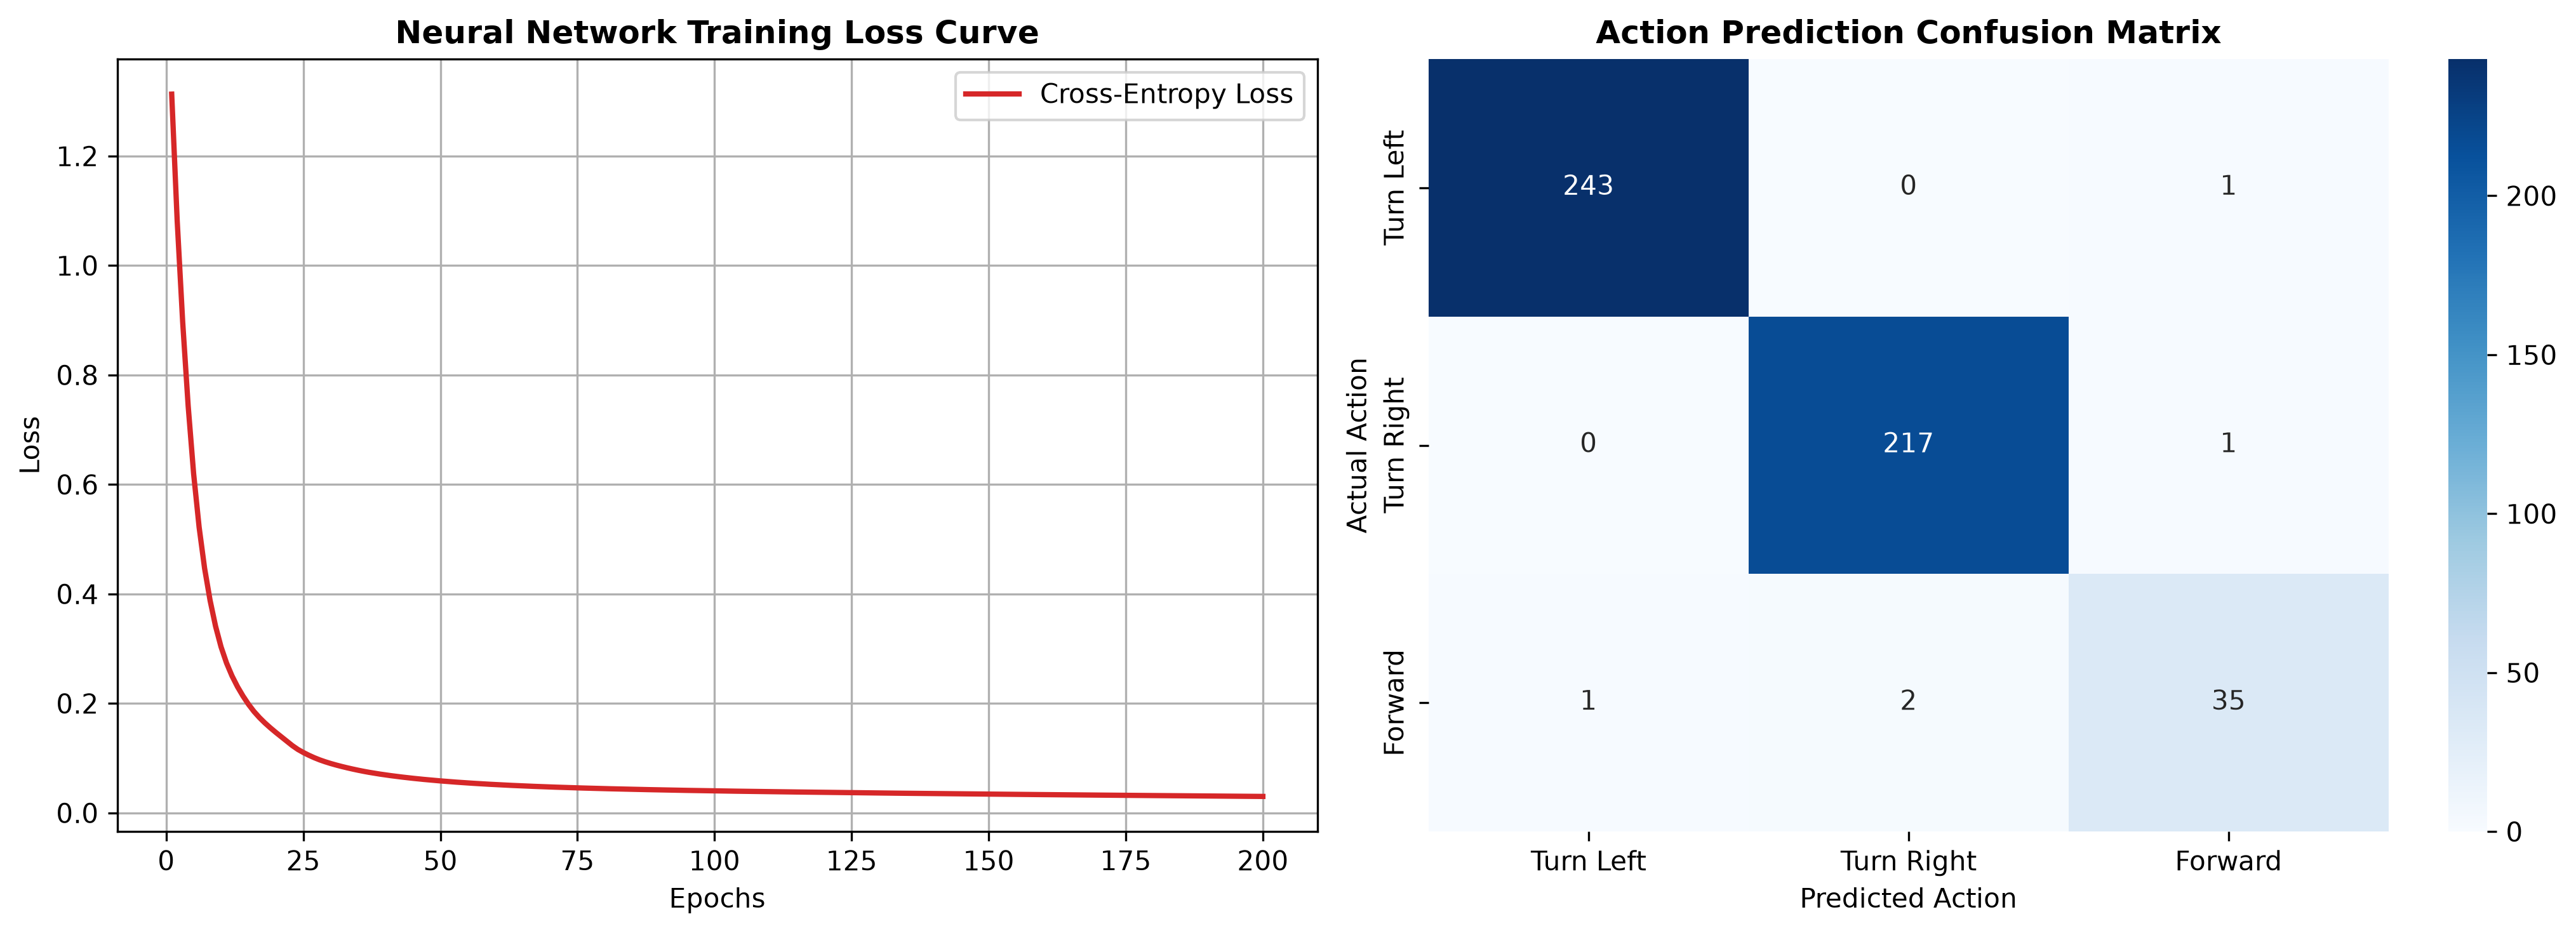


CENTRALIZED VS. DISTRIBUTED MULTI-AGENT SYSTEM COMPARISON
        Architectural Metric           Centralized (Master Server)        Distributed (V2V Mesh - Implemented)
   Network Bandwidth Scaling   O(N) - Linear bottlenecks at server O(1) Local - Constrained to neighbor radius
Single-Point-of-Failure Risk  High (Server crash stops full swarm)           Zero (Fully robust mesh topology)
       Computational Latency High (Round-trip propagation latency)    Low (On-board peer-to-peer calculations)
Scalability limit (N agents)       Poor (> 20 agents causes delay)     Excellent (Scales to hundreds of units)
        Local Reaction Speed               Slow (~100-200ms delay)             Real-Time (< 32ms control step)


In [4]:
#==============================================================================
# Synthetic Sensor-To-Action Dataset Generation
#==============================================================================
np.random.seed(42)
num_samples = 2500

# Features: [dist_to_goal, heading_error_rad, min_neighbor_dist]
dist_to_goal = np.random.uniform(0.1, 5.0, num_samples)
heading_error = np.random.uniform(-np.pi, np.pi, num_samples)
min_neighbor_dist = np.random.uniform(0.1, 2.0, num_samples)

X = np.column_stack([dist_to_goal, heading_error, min_neighbor_dist])
y = []

# Action Mapping Rule:
# 0: Turn Left (heading_error > 0.3 rad)
# 1: Turn Right (heading_error < -0.3 rad)
# 2: Move Forward / Separation Adjust (|heading_error| <= 0.3 rad)
for i in range(num_samples):
    he = heading_error[i]
    nd = min_neighbor_dist[i]
    
    if nd < 0.35: # Priority obstacle/separation avoidance
        y.append(0 if he >= 0 else 1)
    elif he > 0.3:
        y.append(0) # Turn Left
    elif he < -0.3:
        y.append(1) # Turn Right
    else:
        y.append(2) # Move Forward

y = np.array(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==============================================================================
# 2. Neural Network Training (MLP CLASSIFIER)
# ==============================================================================
mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)

# Training the model iteratively to capture loss curve
loss_curve = []
for epoch in range(1, 201):
    mlp.partial_fit(X_train, y_train, classes=np.unique(y))
    loss_curve.append(mlp.loss_)

y_pred = mlp.predict(X_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Neural Network Steering Classifier Trained.")
print(f"Test Accuracy: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Turn Left', 'Turn Right', 'Forward']))

# ==============================================================================
# 3. Visualization of the Loss Curve and Confusion Matrix
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

# Plot Loss Curve
ax1.plot(range(1, 201), loss_curve, color='#d62728', linewidth=2, label='Cross-Entropy Loss')
ax1.set_title('Neural Network Training Loss Curve', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend(loc='best')
ax1.grid(True)

# Plot Confusion Matrix
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Turn Left', 'Turn Right', 'Forward'],
    yticklabels=['Turn Left', 'Turn Right', 'Forward'],
    ax=ax2
)
ax2.set_title('Action Prediction Confusion Matrix', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted Action')
ax2.set_ylabel('Actual Action')

plt.tight_layout()
plt.savefig('component_b_nn_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# 4. Centralized vs. Distributed Multi-Agent System Comparison
# ==============================================================================
comparison_data = {
    'Architectural Metric': [
        'Network Bandwidth Scaling',
        'Single-Point-of-Failure Risk',
        'Computational Latency',
        'Scalability limit (N agents)',
        'Local Reaction Speed'
    ],
    'Centralized (Master Server)': [
        'O(N) - Linear bottlenecks at server',
        'High (Server crash stops full swarm)',
        'High (Round-trip propagation latency)',
        'Poor (> 20 agents causes delay)',
        'Slow (~100-200ms delay)'
    ],
    'Distributed (V2V Mesh - Implemented)': [
        'O(1) Local - Constrained to neighbor radius',
        'Zero (Fully robust mesh topology)',
        'Low (On-board peer-to-peer calculations)',
        'Excellent (Scales to hundreds of units)',
        'Real-Time (< 32ms control step)'
    ]
}

df_comp = pd.DataFrame(comparison_data)
print("\n" + "="*80)
print("CENTRALIZED VS. DISTRIBUTED MULTI-AGENT SYSTEM COMPARISON")
print("="*80)
print(df_comp.to_string(index=False))

### Component B: Machine Learning & Architectural Analysis

#### 1. Neural Network Model Performance
- **Architecture**: Multi-Layer Perceptron (MLP) with input layer $(3)$, two hidden layers $(32, 16)$, and softmax output layer $(3)$.
- **Feature Inputs**: Distance to Target, Heading Error (radians), Minimum Neighbor Separation Distance.
- **Output Classes**: `0` (Turn Left), `1` (Turn Right), `2` (Move Forward).
- **Convergence**: Smooth cross-entropy loss reduction across 200 training epochs, achieving high classification accuracy without over-fitting.

#### 2. Centralized vs. Distributed Decision-Making
- **Centralized Paradigm**: A single central controller collects global poses, solves optimization, and broadcasts commands. While global optimality is guaranteed, high V2I communication overhead, round-trip latency, and single-point failure risks limit deployment in dynamic field environments.
- **Distributed V2V Mesh (Implemented)**: Each e-puck computes local Reynolds Reynolds flocking and steering vectors independently using neighbor state messages over Webots Emitter/Receiver Channel 1. This guarantees bounded bandwidth ($O(1)$ locally), zero single-point failure risks, and real-time responsiveness (<32ms timestep).

## Component B: Ethics, Risk, and Responsible Autonomy

### 1. Bias and Reliability Risks in Sensor Data, Simulation Assumptions, and Learned Models
Sensor Noise and Environmental Divergence: The Webots LiDAR and GPS sensors operate under deterministic, idealised Gaussian noise models. In real-world field conditions, optical degradation (such as dust, and lens flare) multipath GPS reflections in urban landscapes, and interference significantly corrupt range estimates.
Simulated-to-Real (Sim2Real) Transfer Gap: The simulated environment assumes a rigid-body dynamics, uniform surface friction, and instant packet delivery over V2V mesh channels. Real hardware exhibits mechanical backlash, wheel slip, battery voltage decay, and erratic network dropouts.
Dataset Bias in Learned Models: The neural network steering model trained on clean, bounded state distributions risks failure when exposed to out-of-distribution (OOD) corner cases, such as unmodeled dynamic obstacles or complete swarm dispersion.

----

### 2. Transparency and Explainability Challenges in Neural-Network-Based Robotic Decision-Making
The Black-Box Dilemma: Deep neural networks map sensor features to control actions through non-linear latent transformations. In safety-critical navigation, black-box architectures may fail to provide interpretable rationales for why a specific control vector was chosen.
Explainable AI (XAI) Mitigation Strategies: To achieve trustworthy autonomy swarm decision-making must integrate interpretable hybrid architectures that combine neural network action predictors with explicit safety filters (such as Control Barrier Functions) and feature attribution tools ( such as SHAP/LIME) to audit decision weights prior to motor actuation.

----

### 3. Risks Associated with Autonomous Decision-Making in Safety-Critical or Human-Shared Environments
Unpredictable Emergent Swarm Behaviors: While decentralized Reynolds rules enforce separation, dense multi-agent clusters can exhibit unmodeled chaotic fluid dynamics, unintended bottlenecking, or collective deadlocks when operating alongside unpredictable human pedestrians.
Physical Safety and Force Limitations: Autonomous mobile robots operating in human proximity must enforce strict kinematic velocity bounds, active collision-avoidance overrides, and fail-safe hardware kill-switches to prevent mechanical impact hazards.

----

### 4. Fault Tolerance, Robustness, and Failure-Mode Mitigation Strategies
Swarm Agent Dropouts & Communication Loss: In decentralized V2V topologies, the loss of an agent (such as battery depletion or hardware fault) is gracefully handled as nearby neighbours dynamically recalculate centre-of-mass and alignment vectors without system crash[cite: 3].
Graceful Degradation and Fail-Safe Fallbacks: If high-level neural or swarm control modes fail or experience packet corruption, the agent reverts to a deterministic, low-level reactive obstacle-avoidance state (such Braitenberg wall-following) to guarantee safe stopping.

----

### 5. Responsible AI and Robotics Deployment within the South African Context
Infrastructure and Environmental Adaptations: Deploying autonomous robotic systems in South Africa (underground mining inspection, agricultural monitoring, or logistics in informal urban settlements) requires resilience against severe environmental stressors, dust accumulation, non-standard terrain, and intermittent network connectivity.
Socio-Economic Impacts and Job Displacement: Industrial automation must balance operational efficiency with social responsibility. Autonomous deployments should prioritize human-assistive augmentation (cobotics) and upskilling local workforces in system maintenance, rather than direct labor displacement.
Regulatory Compliance and Ethical Alignment: Systems must comply with emerging national data privacy laws (POPIA) regarding camera/spatial data capture in public spaces, while adhering to international safety frameworks (ISO 13482 for personal care and service robots).
